In [2]:
!pip -q install pandas numpy matplotlib seaborn networkx plotly folium

In [3]:
from google.colab import files

uploaded = files.upload()

Saving iot_edge_computing_public_management.csv to iot_edge_computing_public_management.csv


In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import networkx as nx
import plotly.express as px
import plotly.graph_objects as go

import folium

import warnings
warnings.filterwarnings("ignore")

# Professional visualization settings
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.labelweight": "semibold"
})

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("iot_edge_computing_public_management.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1000, 9)


,timestamp,sensor_id,vehicle_speed (km/h),latitude,longitude,traffic_pattern,incident_report,accident_hotspot,event_type
0,2024-12-06 08:00:00,Vehicle_1,114,34.549262,-79.301369,Clear,NaN,0,Accident
1,2024-12-06 08:15:00,Vehicle_2,63,36.818973,-97.578931,Heavy,Breakdown,1,Normal
2,2024-12-06 08:30:00,Vehicle_3,67,39.896045,-111.733975,Moderate,Police Blockade,0,Accident
3,2024-12-06 08:45:00,Vehicle_4,24,34.220403,-99.540879,Moderate,Police Blockade,0,Congestion
4,2024-12-06 09:00:00,Vehicle_5,62,38.484415,-109.623058,Heavy,Accident,0,Congestion


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows: 1000
Number of columns: 9

Column names:
['timestamp', 'sensor_id', 'vehicle_speed (km/h)', 'latitude', 'longitude', 'traffic_pattern', 'incident_report', 'accident_hotspot', 'event_type']

Data types:
timestamp                object
sensor_id                object
vehicle_speed (km/h)      int64
latitude                float64
longitude               float64
traffic_pattern          object
incident_report          object
accident_hotspot          int64
event_type               object
dtype: object


In [7]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values
})

display(missing_table)

,Column,Missing Values
0,timestamp,0
1,sensor_id,0
2,vehicle_speed (km/h),0
3,latitude,0
4,longitude,0
5,traffic_pattern,0
6,incident_report,232
7,accident_hotspot,0
8,event_type,0


In [9]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Fill missing incident reports
df["incident_report"] = df["incident_report"].fillna(
    "No Report"
)

# Remove completely duplicated records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (1000, 9)


,timestamp,sensor_id,vehicle_speed (km/h),latitude,longitude,traffic_pattern,incident_report,accident_hotspot,event_type
0,2024-12-06 08:00:00,Vehicle_1,114,34.549262,-79.301369,Clear,No Report,0,Accident
1,2024-12-06 08:15:00,Vehicle_2,63,36.818973,-97.578931,Heavy,Breakdown,1,Normal
2,2024-12-06 08:30:00,Vehicle_3,67,39.896045,-111.733975,Moderate,Police Blockade,0,Accident
3,2024-12-06 08:45:00,Vehicle_4,24,34.220403,-99.540879,Moderate,Police Blockade,0,Congestion
4,2024-12-06 09:00:00,Vehicle_5,62,38.484415,-109.623058,Heavy,Accident,0,Congestion


In [10]:
df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_name()

display(
    df[
        [
            "timestamp",
            "date",
            "hour",
            "day_of_week"
        ]
    ].head()
)

,timestamp,date,hour,day_of_week
0,2024-12-06 08:00:00,2024-12-06,8,Friday
1,2024-12-06 08:15:00,2024-12-06,8,Friday
2,2024-12-06 08:30:00,2024-12-06,8,Friday
3,2024-12-06 08:45:00,2024-12-06,8,Friday
4,2024-12-06 09:00:00,2024-12-06,9,Friday


In [11]:
print("Traffic Dataset Summary")
print("=" * 50)

print("Total records:", len(df))
print(
    "Average vehicle speed:",
    round(df["vehicle_speed (km/h)"].mean(), 2),
    "km/h"
)

print(
    "Minimum speed:",
    df["vehicle_speed (km/h)"].min(),
    "km/h"
)

print(
    "Maximum speed:",
    df["vehicle_speed (km/h)"].max(),
    "km/h"
)

print(
    "Accident hotspots:",
    df["accident_hotspot"].sum()
)

Traffic Dataset Summary
Total records: 1000
Average vehicle speed: 70.39 km/h
Minimum speed: 20 km/h
Maximum speed: 120 km/h
Accident hotspots: 155


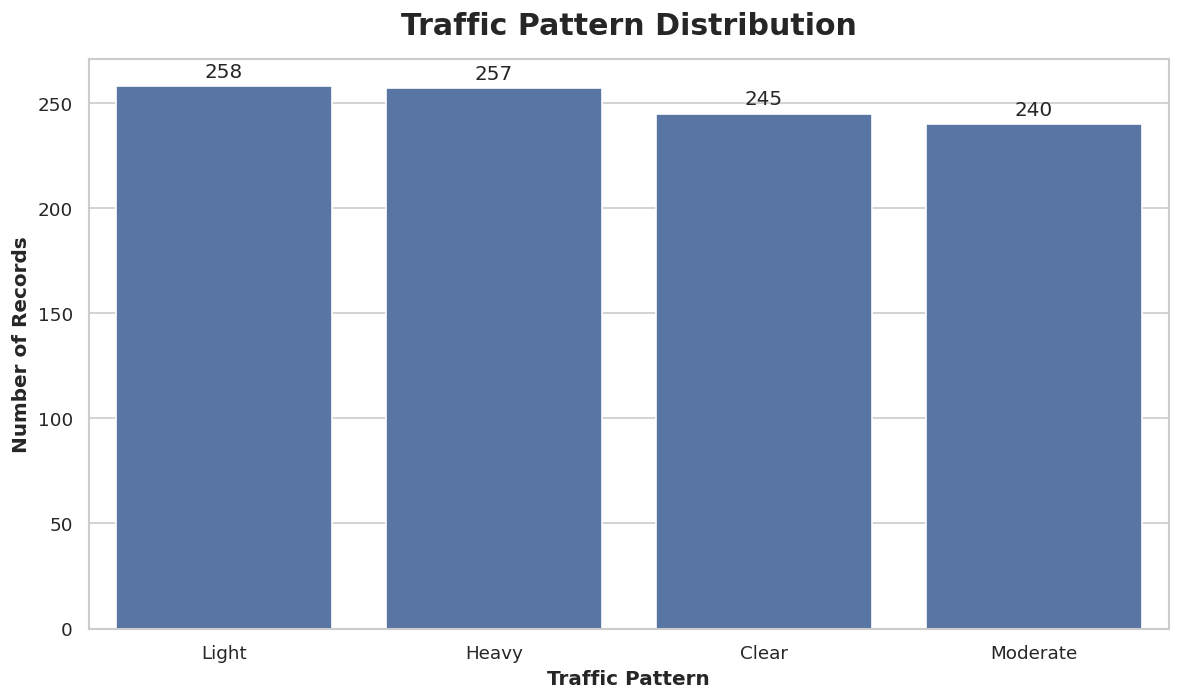

In [12]:
pattern_counts = (
    df["traffic_pattern"]
    .value_counts()
    .reset_index()
)

pattern_counts.columns = [
    "Traffic Pattern",
    "Count"
]

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=pattern_counts,
    x="Traffic Pattern",
    y="Count",
    ax=ax
)

ax.set_title(
    "Traffic Pattern Distribution",
    fontsize=18,
    pad=15
)

ax.set_xlabel("Traffic Pattern")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()
plt.show()

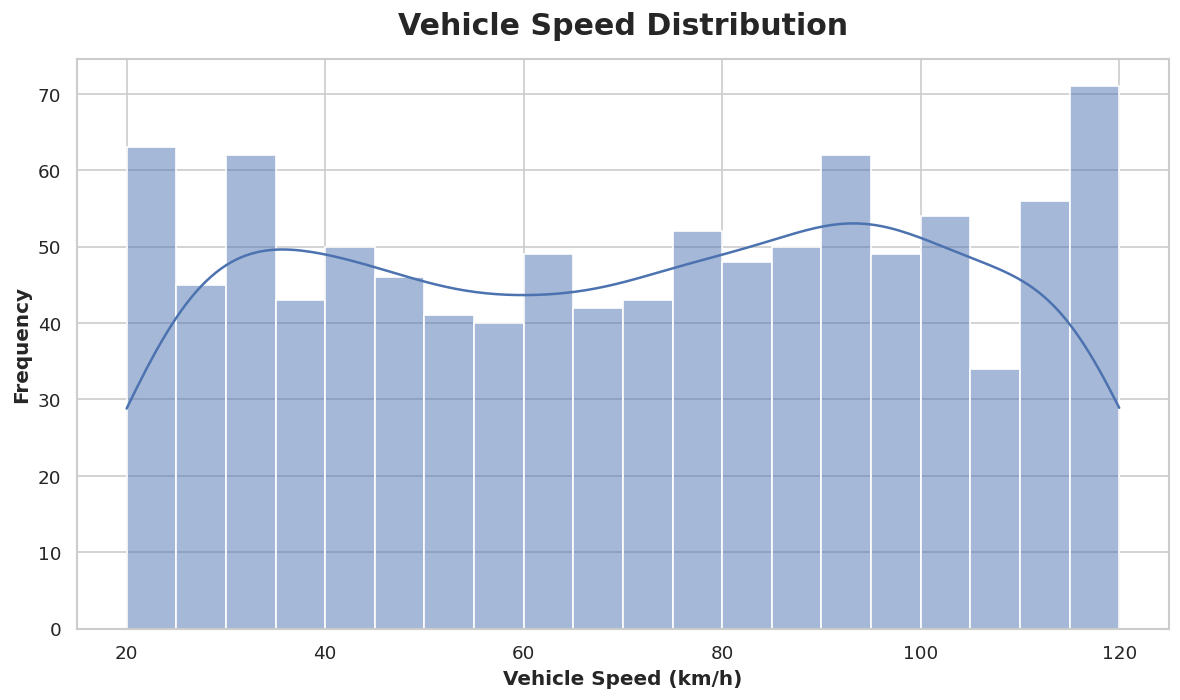

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df,
    x="vehicle_speed (km/h)",
    bins=20,
    kde=True,
    ax=ax
)

ax.set_title(
    "Vehicle Speed Distribution",
    fontsize=18,
    pad=15
)

ax.set_xlabel("Vehicle Speed (km/h)")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

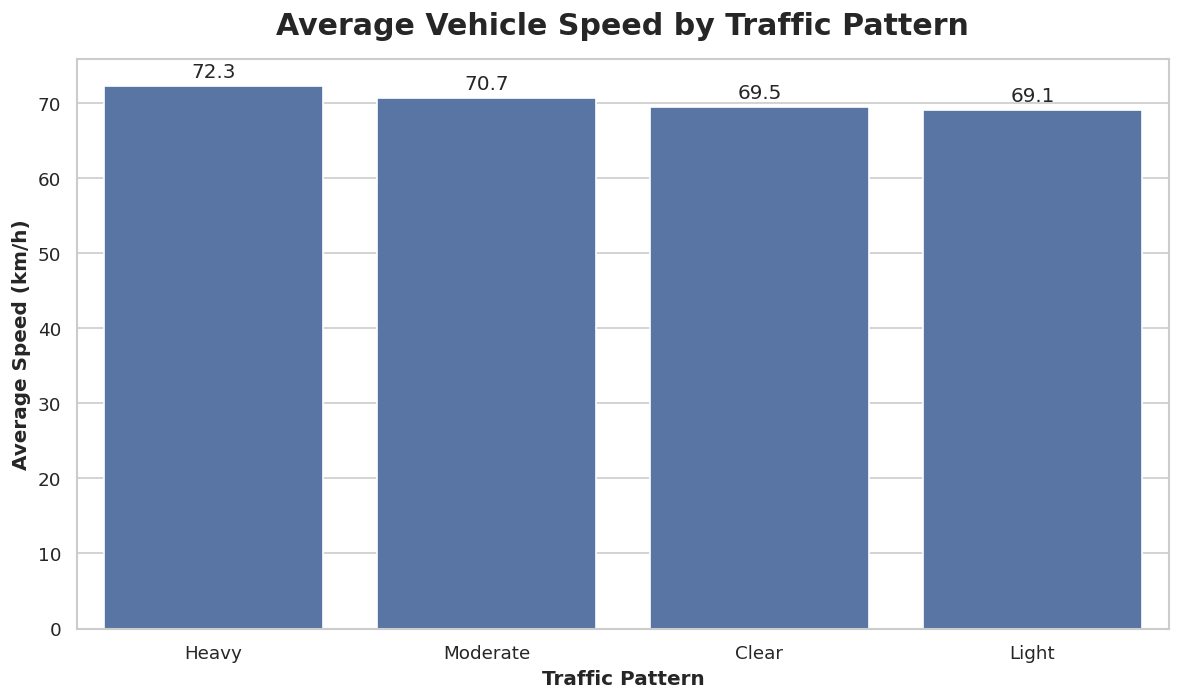

In [14]:
speed_pattern = (
    df.groupby("traffic_pattern")["vehicle_speed (km/h)"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

speed_pattern.columns = [
    "Traffic Pattern",
    "Average Speed"
]

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=speed_pattern,
    x="Traffic Pattern",
    y="Average Speed",
    ax=ax
)

ax.set_title(
    "Average Vehicle Speed by Traffic Pattern",
    fontsize=18,
    pad=15
)

ax.set_ylabel("Average Speed (km/h)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3
    )

plt.tight_layout()
plt.show()

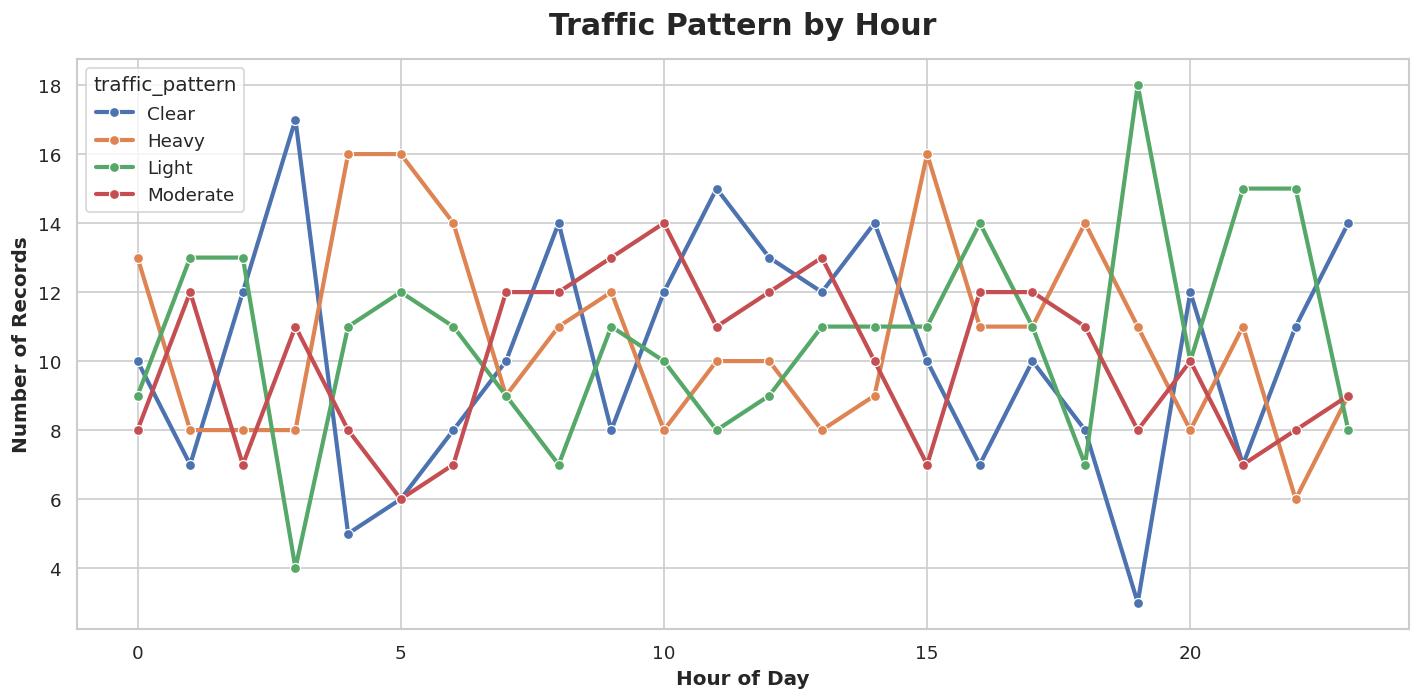

In [16]:
hourly_traffic = (
    df.groupby(["hour", "traffic_pattern"])
    .size()
    .reset_index(name="Count")
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=hourly_traffic,
    x="hour",
    y="Count",
    hue="traffic_pattern",
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.set_title(
    "Traffic Pattern by Hour",
    fontsize=18,
    pad=15
)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

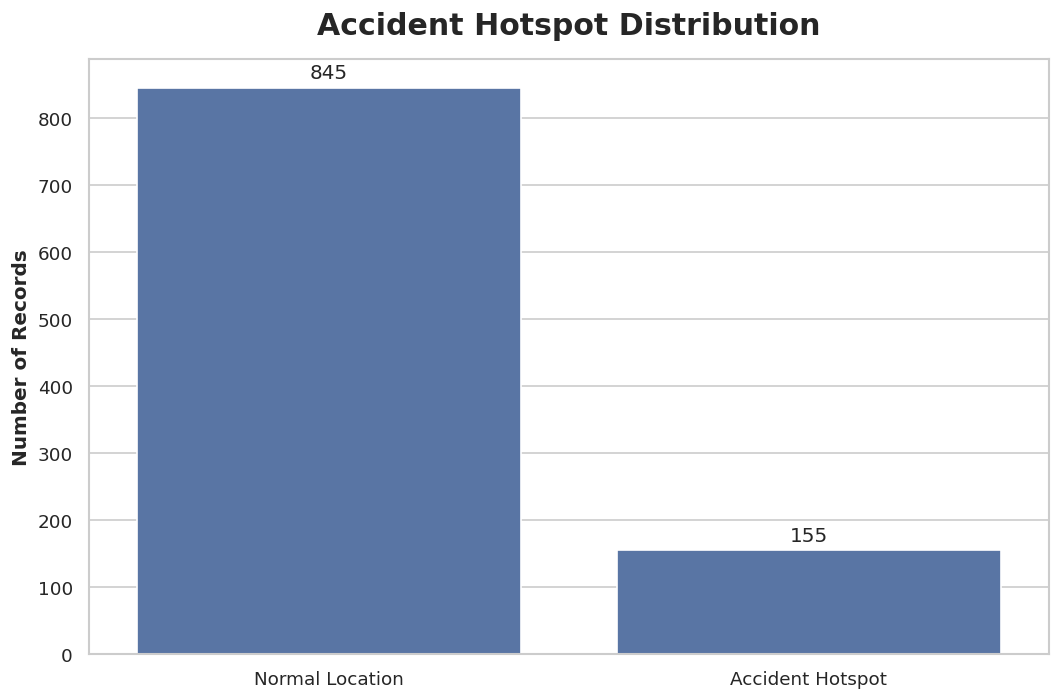

In [17]:
hotspot_counts = (
    df["accident_hotspot"]
    .value_counts()
    .sort_index()
)

labels = [
    "Normal Location",
    "Accident Hotspot"
]

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    x=labels,
    y=[
        hotspot_counts.get(0, 0),
        hotspot_counts.get(1, 0)
    ],
    ax=ax
)

ax.set_title(
    "Accident Hotspot Distribution",
    fontsize=18,
    pad=15
)

ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()
plt.show()

,Incident,Count
0,No Report,232
1,Traffic Jam,206
2,Accident,196
3,Police Blockade,183
4,Breakdown,183


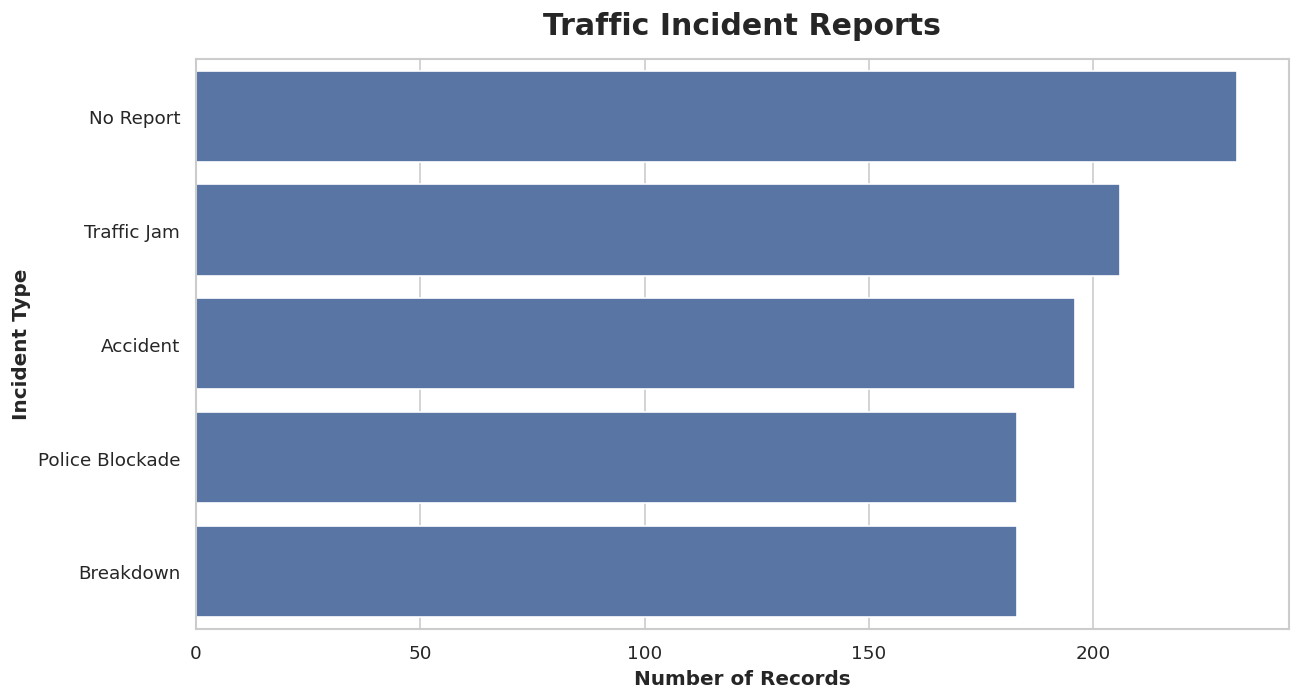

In [19]:
incident_counts = (
    df["incident_report"]
    .value_counts()
    .reset_index()
)

incident_counts.columns = [
    "Incident",
    "Count"
]

display(incident_counts)
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=incident_counts,
    x="Count",
    y="Incident",
    ax=ax
)

ax.set_title(
    "Traffic Incident Reports",
    fontsize=18,
    pad=15
)

ax.set_xlabel("Number of Records")
ax.set_ylabel("Incident Type")

plt.tight_layout()
plt.show()

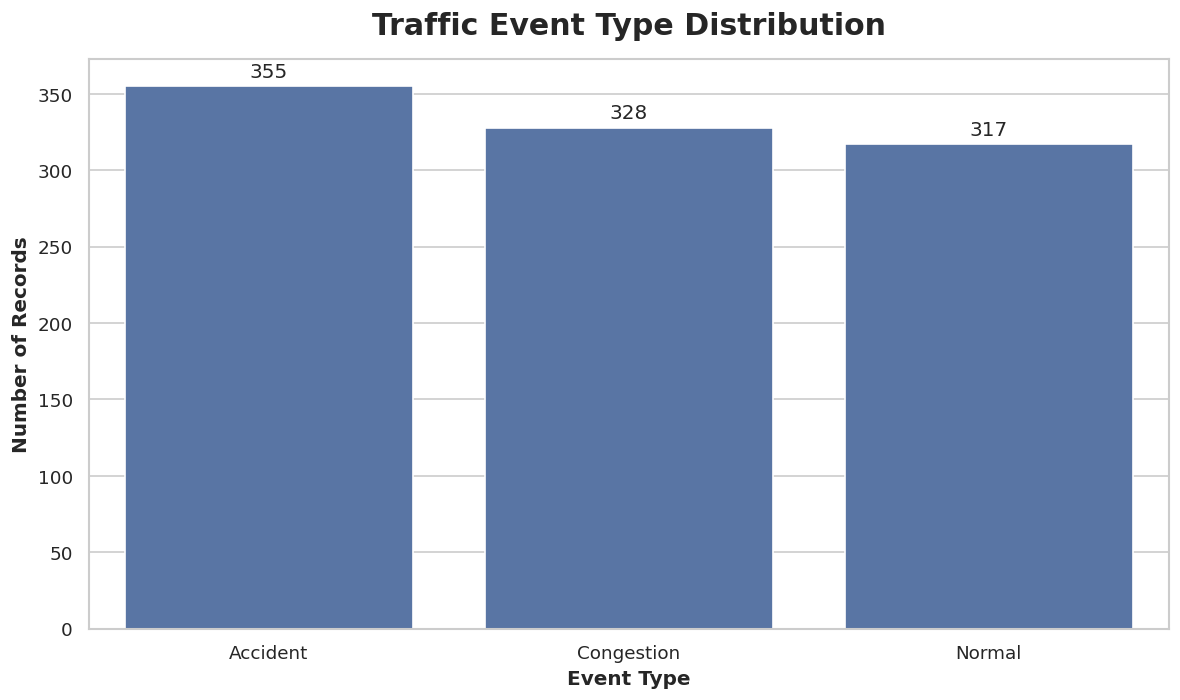

In [20]:
event_counts = (
    df["event_type"]
    .value_counts()
    .reset_index()
)

event_counts.columns = [
    "Event Type",
    "Count"
]

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=event_counts,
    x="Event Type",
    y="Count",
    ax=ax
)

ax.set_title(
    "Traffic Event Type Distribution",
    fontsize=18,
    pad=15
)

ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()
plt.show()

In [21]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from folium.plugins import MarkerCluster
from streamlit_folium import st_folium

from math import radians, sin, cos, sqrt, atan2

# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Traffic Network Analytics",
    page_icon="🚦",
    layout="wide"
)

# ============================================================
# CUSTOM CSS
# ============================================================

st.markdown("""
<style>

.main {
    background-color: #f5f7fa;
}

.block-container {
    padding-top: 1.5rem;
}

.dashboard-title {
    font-size: 38px;
    font-weight: 700;
    color: #19304d;
    margin-bottom: 5px;
}

.dashboard-subtitle {
    font-size: 17px;
    color: #64748b;
    margin-bottom: 25px;
}

.section-title {
    font-size: 27px;
    font-weight: 700;
    color: #19304d;
    margin-top: 25px;
}

.kpi-card {
    background-color: white;
    padding: 20px;
    border-radius: 12px;
    border: 1px solid #dce3eb;
    text-align: center;
}

.kpi-value {
    font-size: 30px;
    font-weight: 700;
    color: #2d69af;
}

.kpi-label {
    font-size: 14px;
    color: #64748b;
}

</style>
""", unsafe_allow_html=True)


# ============================================================
# FUNCTIONS
# ============================================================

def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371.0

    lat1, lon1, lat2, lon2 = map(
        radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        +
        cos(lat1)
        * cos(lat2)
        * sin(dlon / 2) ** 2
    )

    c = 2 * atan2(
        sqrt(a),
        sqrt(1 - a)
    )

    return R * c


@st.cache_data
def prepare_data(data):

    data = data.copy()

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

    data["incident_report"] = (
        data["incident_report"]
        .fillna("No Report")
    )

    data = data.drop_duplicates()

    data = data.dropna(
        subset=[
            "sensor_id",
            "latitude",
            "longitude"
        ]
    )

    data["date"] = data["timestamp"].dt.date

    data["hour"] = data["timestamp"].dt.hour

    data["day_of_week"] = (
        data["timestamp"].dt.day_name()
    )

    return data.reset_index(drop=True)


def build_sensor_locations(data):

    locations = (
        data.groupby("sensor_id")
        .agg({
            "latitude": "mean",
            "longitude": "mean",
            "vehicle_speed (km/h)": "mean",
            "accident_hotspot": "max",
            "traffic_pattern": (
                lambda x:
                x.mode().iloc[0]
                if not x.mode().empty
                else "Unknown"
            )
        })
        .reset_index()
    )

    return locations


def build_graph(sensor_locations):

    G = nx.Graph()

    for _, row in sensor_locations.iterrows():

        G.add_node(
            row["sensor_id"],
            latitude=row["latitude"],
            longitude=row["longitude"],
            traffic_pattern=row["traffic_pattern"],
            average_speed=row[
                "vehicle_speed (km/h)"
            ],
            accident_hotspot=row[
                "accident_hotspot"
            ]
        )

    locations = sensor_locations.to_dict(
        "records"
    )

    for i, source in enumerate(locations):

        distances = []

        for j, target in enumerate(locations):

            if i == j:
                continue

            distance = haversine_distance(
                source["latitude"],
                source["longitude"],
                target["latitude"],
                target["longitude"]
            )

            distances.append(
                (
                    distance,
                    target["sensor_id"]
                )
            )

        distances.sort()

        # Connect each sensor to nearest 3
        for distance, target_id in distances[:3]:

            G.add_edge(
                source["sensor_id"],
                target_id,
                distance_km=distance
            )

    return G


def add_traffic_costs(G, sensor_traffic):

    traffic_factor = {
        "Clear": 1.0,
        "Moderate": 1.3,
        "Heavy": 1.7
    }

    for u, v, data in G.edges(
        data=True
    ):

        traffic_u = sensor_traffic.get(
            u,
            "Moderate"
        )

        traffic_v = sensor_traffic.get(
            v,
            "Moderate"
        )

        factor_u = traffic_factor.get(
            traffic_u,
            1.3
        )

        factor_v = traffic_factor.get(
            traffic_v,
            1.3
        )

        average_factor = (
            factor_u + factor_v
        ) / 2

        data["traffic_cost"] = (
            data["distance_km"]
            * average_factor
        )

    return G


# ============================================================
# HEADER
# ============================================================

st.markdown(
    '<div class="dashboard-title">🚦 Traffic Network Analytics</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="dashboard-subtitle">'
    'Web-Based Traffic Network Analysis and Route Optimization'
    '</div>',
    unsafe_allow_html=True
)


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("⚙️ Project Controls")

uploaded_file = st.sidebar.file_uploader(
    "Upload Traffic CSV",
    type=["csv"]
)

if uploaded_file is None:

    st.info(
        "👈 Upload your traffic CSV file from the sidebar to start the dashboard."
    )

    st.markdown("""
    ### Project Modules

    **📊 Traffic Analytics**

    Analyze traffic patterns, speeds and events.

    **🗺️ Interactive Map**

    Explore traffic sensors and accident hotspots.

    **🕸️ Traffic Network**

    Build a graph from nearby sensor locations.

    **📍 Centrality Analysis**

    Analyze degree and betweenness centrality.

    **🛣️ Route Optimization**

    Compare shortest-distance and traffic-aware routes.
    """)

    st.stop()


# ============================================================
# LOAD DATA
# ============================================================

try:

    raw_df = pd.read_csv(
        uploaded_file
    )

except Exception as e:

    st.error(
        f"Unable to read the CSV file: {e}"
    )

    st.stop()


# ============================================================
# VALIDATE COLUMNS
# ============================================================

required_columns = [
    "timestamp",
    "sensor_id",
    "vehicle_speed (km/h)",
    "latitude",
    "longitude",
    "traffic_pattern",
    "incident_report",
    "accident_hotspot",
    "event_type"
]

missing_columns = [
    col
    for col in required_columns
    if col not in raw_df.columns
]

if missing_columns:

    st.error(
        "The uploaded dataset is missing these columns:"
    )

    st.write(
        missing_columns
    )

    st.stop()


# ============================================================
# CLEAN DATA
# ============================================================

df = prepare_data(raw_df)

sensor_locations = build_sensor_locations(
    df
)

G = build_graph(
    sensor_locations
)


# ============================================================
# KPI SECTION
# ============================================================

st.markdown(
    '<div class="section-title">📊 Traffic Overview</div>',
    unsafe_allow_html=True
)

col1, col2, col3, col4 = st.columns(4)

with col1:

    st.metric(
        "Total Records",
        f"{len(df):,}"
    )

with col2:

    st.metric(
        "Traffic Sensors",
        f"{df['sensor_id'].nunique():,}"
    )

with col3:

    st.metric(
        "Average Speed",
        f"{df['vehicle_speed (km/h)'].mean():.2f} km/h"
    )

with col4:

    st.metric(
        "Accident Hotspots",
        f"{int(df['accident_hotspot'].sum()):,}"
    )


# ============================================================
# TRAFFIC ANALYTICS
# ============================================================

st.markdown(
    '<div class="section-title">📊 Traffic Analytics</div>',
    unsafe_allow_html=True
)

col1, col2 = st.columns(2)

with col1:

    pattern_counts = (
        df["traffic_pattern"]
        .value_counts()
        .reset_index()
    )

    pattern_counts.columns = [
        "Traffic Pattern",
        "Count"
    ]

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    sns.barplot(
        data=pattern_counts,
        x="Traffic Pattern",
        y="Count",
        ax=ax
    )

    ax.set_title(
        "Traffic Pattern Distribution"
    )

    ax.set_xlabel(
        "Traffic Pattern"
    )

    ax.set_ylabel(
        "Number of Records"
    )

    st.pyplot(
        fig,
        use_container_width=True
    )

    plt.close(fig)


with col2:

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    sns.histplot(
        data=df,
        x="vehicle_speed (km/h)",
        bins=20,
        kde=True,
        ax=ax
    )

    ax.set_title(
        "Vehicle Speed Distribution"
    )

    ax.set_xlabel(
        "Vehicle Speed (km/h)"
    )

    ax.set_ylabel(
        "Frequency"
    )

    st.pyplot(
        fig,
        use_container_width=True
    )

    plt.close(fig)


# ============================================================
# SPEED BY TRAFFIC PATTERN
# ============================================================

speed_pattern = (
    df.groupby(
        "traffic_pattern"
    )["vehicle_speed (km/h)"]
    .mean()
    .reset_index()
)

speed_pattern.columns = [
    "Traffic Pattern",
    "Average Speed"
]

fig, ax = plt.subplots(
    figsize=(10, 5)
)

sns.barplot(
    data=speed_pattern,
    x="Traffic Pattern",
    y="Average Speed",
    ax=ax
)

ax.set_title(
    "Average Vehicle Speed by Traffic Pattern"
)

ax.set_ylabel(
    "Average Speed (km/h)"
)

st.pyplot(
    fig,
    use_container_width=True
)

plt.close(fig)


# ============================================================
# HOURLY TRAFFIC
# ============================================================

hourly_traffic = (
    df.groupby(
        ["hour", "traffic_pattern"]
    )
    .size()
    .reset_index(
        name="Count"
    )
)

fig, ax = plt.subplots(
    figsize=(11, 5)
)

sns.lineplot(
    data=hourly_traffic,
    x="hour",
    y="Count",
    hue="traffic_pattern",
    marker="o",
    ax=ax
)

ax.set_title(
    "Traffic Pattern by Hour"
)

ax.set_xlabel(
    "Hour of Day"
)

ax.set_ylabel(
    "Number of Records"
)

st.pyplot(
    fig,
    use_container_width=True
)

plt.close(fig)


# ============================================================
# INTERACTIVE MAP
# ============================================================

st.markdown(
    '<div class="section-title">🗺️ Interactive Traffic Map</div>',
    unsafe_allow_html=True
)

center_lat = sensor_locations[
    "latitude"
].mean()

center_lon = sensor_locations[
    "longitude"
].mean()

traffic_map = folium.Map(
    location=[
        center_lat,
        center_lon
    ],
    zoom_start=5,
    tiles="OpenStreetMap"
)

marker_cluster = MarkerCluster().add_to(
    traffic_map
)

for _, row in sensor_locations.iterrows():

    popup = f"""
    <b>Sensor:</b> {row['sensor_id']}<br>
    <b>Average Speed:</b>
    {row['vehicle_speed (km/h)']:.2f} km/h<br>
    <b>Traffic Pattern:</b>
    {row['traffic_pattern']}<br>
    <b>Accident Hotspot:</b>
    {row['accident_hotspot']}
    """

    folium.Marker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        popup=folium.Popup(
            popup,
            max_width=300
        ),
        tooltip=str(
            row["sensor_id"]
        )
    ).add_to(
        marker_cluster
    )

st_folium(
    traffic_map,
    width=1200,
    height=550
)


# ============================================================
# ACCIDENT HOTSPOT MAP
# ============================================================

st.markdown(
    '<div class="section-title">📍 Accident Hotspot Map</div>',
    unsafe_allow_html=True
)

hotspot_map = folium.Map(
    location=[
        center_lat,
        center_lon
    ],
    zoom_start=5,
    tiles="OpenStreetMap"
)

hotspot_data = df[
    df["accident_hotspot"] == 1
]

for _, row in hotspot_data.iterrows():

    popup = f"""
    <b>Sensor:</b> {row['sensor_id']}<br>
    <b>Speed:</b>
    {row['vehicle_speed (km/h)']} km/h<br>
    <b>Traffic:</b>
    {row['traffic_pattern']}<br>
    <b>Event:</b>
    {row['event_type']}<br>
    <b>Incident:</b>
    {row['incident_report']}
    """

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        radius=6,
        popup=folium.Popup(
            popup,
            max_width=350
        ),
        fill=True
    ).add_to(
        hotspot_map
    )

st_folium(
    hotspot_map,
    width=1200,
    height=500
)


# ============================================================
# TRAFFIC NETWORK
# ============================================================

st.markdown(
    '<div class="section-title">🕸️ Traffic Sensor Network</div>',
    unsafe_allow_html=True
)

col1, col2 = st.columns(2)

with col1:

    st.metric(
        "Network Nodes",
        G.number_of_nodes()
    )

with col2:

    st.metric(
        "Network Edges",
        G.number_of_edges()
    )


fig, ax = plt.subplots(
    figsize=(12, 7)
)

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.25,
    width=1,
    ax=ax
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=80,
    alpha=0.85,
    ax=ax
)

degree_dict = dict(
    G.degree()
)

top_nodes = sorted(
    degree_dict,
    key=degree_dict.get,
    reverse=True
)[:10]

labels = {
    node: node
    for node in top_nodes
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=8,
    ax=ax
)

ax.set_title(
    "Traffic Sensor Network"
)

ax.axis("off")

st.pyplot(
    fig,
    use_container_width=True
)

plt.close(fig)


# ============================================================
# CENTRALITY ANALYSIS
# ============================================================

st.markdown(
    '<div class="section-title">📍 Centrality Analysis</div>',
    unsafe_allow_html=True
)

degree_centrality = nx.degree_centrality(
    G
)

degree_df = (
    pd.DataFrame(
        degree_centrality.items(),
        columns=[
            "Sensor",
            "Degree Centrality"
        ]
    )
    .sort_values(
        "Degree Centrality",
        ascending=False
    )
)

betweenness = nx.betweenness_centrality(
    G
)

between_df = (
    pd.DataFrame(
        betweenness.items(),
        columns=[
            "Sensor",
            "Betweenness Centrality"
        ]
    )
    .sort_values(
        "Betweenness Centrality",
        ascending=False
    )
)

col1, col2 = st.columns(2)

with col1:

    st.subheader(
        "Degree Centrality"
    )

    st.dataframe(
        degree_df.head(10),
        use_container_width=True
    )

with col2:

    st.subheader(
        "Betweenness Centrality"
    )

    st.dataframe(
        between_df.head(10),
        use_container_width=True
    )


top_between = (
    between_df
    .head(10)
    .sort_values(
        "Betweenness Centrality"
    )
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.barplot(
    data=top_between,
    x="Betweenness Centrality",
    y="Sensor",
    ax=ax
)

ax.set_title(
    "Top Sensors by Betweenness Centrality"
)

st.pyplot(
    fig,
    use_container_width=True
)

plt.close(fig)


# ============================================================
# ROUTE OPTIMIZATION
# ============================================================

st.markdown(
    '<div class="section-title">🛣️ Route Optimization</div>',
    unsafe_allow_html=True
)

nodes = sorted(
    list(G.nodes())
)

if len(nodes) >= 2:

    col1, col2 = st.columns(2)

    with col1:

        source = st.selectbox(
            "Select Source Sensor",
            nodes,
            index=0
        )

    with col2:

        destination_options = [
            node
            for node in nodes
            if node != source
        ]

        destination = st.selectbox(
            "Select Destination Sensor",
            destination_options,
            index=0
        )

    if st.button(
        "🚗 Find Optimized Routes",
        use_container_width=True
    ):

        try:

            # Distance route
            shortest_path = nx.shortest_path(
                G,
                source=source,
                target=destination,
                weight="distance_km"
            )

            shortest_distance = (
                nx.shortest_path_length(
                    G,
                    source=source,
                    target=destination,
                    weight="distance_km"
                )
            )

            # Sensor traffic
            sensor_traffic = (
                df.groupby(
                    "sensor_id"
                )["traffic_pattern"]
                .agg(
                    lambda x:
                    x.mode().iloc[0]
                    if not x.mode().empty
                    else "Moderate"
                )
            )

            # Traffic costs
            G = add_traffic_costs(
                G,
                sensor_traffic
            )

            # Traffic-aware route
            optimized_path = nx.shortest_path(
                G,
                source=source,
                target=destination,
                weight="traffic_cost"
            )

            optimized_cost = (
                nx.shortest_path_length(
                    G,
                    source=source,
                    target=destination,
                    weight="traffic_cost"
                )
            )

            st.success(
                "Routes calculated successfully!"
            )

            col1, col2 = st.columns(2)

            with col1:

                st.subheader(
                    "📏 Distance-Based Route"
                )

                st.write(
                    " → ".join(
                        shortest_path
                    )
                )

                st.metric(
                    "Distance",
                    f"{shortest_distance:.2f} km"
                )

            with col2:

                st.subheader(
                    "🚦 Traffic-Aware Route"
                )

                st.write(
                    " → ".join(
                        optimized_path
                    )
                )

                st.metric(
                    "Traffic Cost",
                    f"{optimized_cost:.2f}"
                )

            # Route graph
            fig, ax = plt.subplots(
                figsize=(12, 7)
            )

            pos = nx.spring_layout(
                G,
                seed=42,
                k=0.8
            )

            nx.draw_networkx_edges(
                G,
                pos,
                alpha=0.15,
                ax=ax
            )

            nx.draw_networkx_nodes(
                G,
                pos,
                node_size=70,
                alpha=0.6,
                ax=ax
            )

            route_edges = list(
                zip(
                    optimized_path[:-1],
                    optimized_path[1:]
                )
            )

            nx.draw_networkx_edges(
                G,
                pos,
                edgelist=route_edges,
                width=4,
                ax=ax
            )

            nx.draw_networkx_nodes(
                G,
                pos,
                nodelist=[
                    source,
                    destination
                ],
                node_size=250,
                ax=ax
            )

            nx.draw_networkx_labels(
                G,
                pos,
                labels={
                    source: "SOURCE",
                    destination: "DESTINATION"
                },
                font_size=9,
                ax=ax
            )

            ax.set_title(
                "Traffic-Aware Optimized Route"
            )

            ax.axis("off")

            st.pyplot(
                fig,
                use_container_width=True
            )

            plt.close(fig)

        except nx.NetworkXNoPath:

            st.error(
                "No route exists between the selected sensors."
            )

else:

    st.warning(
        "At least two sensors are required for route optimization."
    )


# ============================================================
# FOOTER
# ============================================================

st.markdown("---")

st.markdown(
    """
    <div style="text-align:center;color:#64748b;">
    🚦 Web-Based Traffic Network Analysis and Route Optimization
    <br>
    Graph and Web Analytics Project
    </div>
    """,
    unsafe_allow_html=True
)

Writing app.py


In [22]:
!pip -q install streamlit streamlit-folium folium networkx matplotlib seaborn pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.9/536.9 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 58.4 MB/s eta 0:00:00


In [26]:
!pip install pyngrok streamlit

In [27]:
!pip install -q pyngrok streamlit

In [28]:
from pyngrok import ngrok
import os
import time
from IPython.display import HTML, display

ngrok.set_auth_token("2yjO8o7P4jYTbiipDO8CvryjyBk_6S5eEN8ZrakxTE4UzXwZd")

ngrok.kill()

file_path = "app.py"

os.system(f"streamlit run {file_path} --server.port 8501 &")

time.sleep(5)

public_url = ngrok.connect(8501)

print(f"Streamlit app is running at: {public_url}")

display(HTML(
    f"<a href='{public_url}' target='_blank'>Click to open Streamlit App</a>"
))

Streamlit app is running at: NgrokTunnel: "https://58d8-34-186-8-187.ngrok-free.app" -> "http://localhost:8501"
